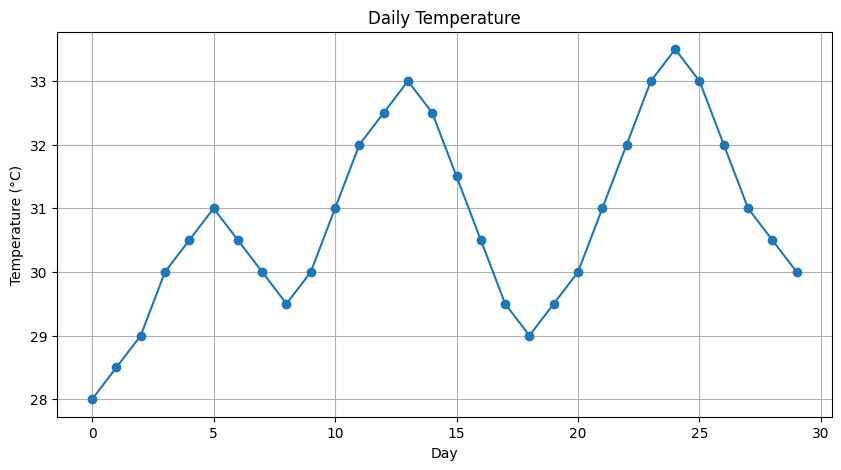

In [14]:
import numpy as np
import matplotlib.pyplot as plt

temperatures = np.array([
    28.0, 28.5, 29.0, 30.0, 30.5,
    31.0, 30.5, 30.0, 29.5, 30.0,
    31.0, 32.0, 32.5, 33.0, 32.5,
    31.5, 30.5, 29.5, 29.0, 29.5,
    30.0, 31.0, 32.0, 33.0, 33.5,
    33.0, 32.0, 31.0, 30.5, 30.0
])

plt.figure(figsize=(10,5))
plt.plot(temperatures, marker='o')

plt.xlabel("Day")
plt.ylabel("Temperature (°C)")
plt.title("Daily Temperature")
plt.grid(True)
plt.show()

In [15]:
window_size = 5

X = []
y = []

for i in range(len(temperatures) - window_size):

    X.append(temperatures[i:i+window_size])

    y.append(temperatures[i+window_size])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (25, 5)
y shape: (25,)


In [16]:
print("Input sequence:")
print(X[0])

print("\nTarget:")
print(y[0])

Input sequence:
[28.  28.5 29.  30.  30.5]

Target:
31.0


In [17]:
X = X.reshape(X.shape[0], X.shape[1], 1)

In [18]:
from tensorflow import keras
from tensorflow.keras import layers

model = keras.Sequential([
    layers.Input(shape=(5, 1)),
    layers.SimpleRNN(16),
    layers.Dense(1)
])

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 16)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 305 (1.19 KB)

 Trainable params: 305 (1.19 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [20]:
history = model.fit(
    X,
    y,
    epochs=100,
    batch_size=4,
    verbose=1
)

Epoch 1/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 969.9263 - mae: 31.1172
Epoch 2/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 962.3948 - mae: 30.9961 
Epoch 3/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 954.7974 - mae: 30.8727  
Epoch 4/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 946.9038 - mae: 30.7451 
Epoch 5/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 938.4385 - mae: 30.6071 
Epoch 6/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 928.7152 - mae: 30.4478 
Epoch 7/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 917.0910 - mae: 30.2554 
Epoch 8/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 903.4373 - mae: 30.0288 
Epoch 9/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 888.0387 - mae: 29.7724 
Epoch 10/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 869.9548 - mae: 29.4665 
Epoch 11/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 845.9260 - mae: 29.0557 
Epoch 12/100
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 821.3749 - mae: 28.6311 
Epoch 13/100


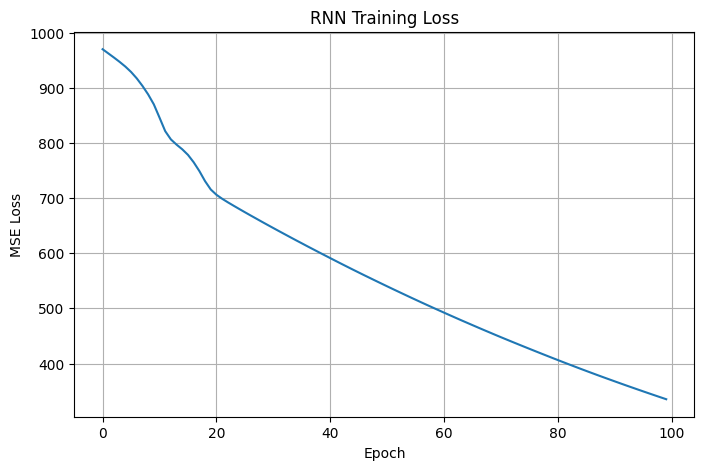

In [21]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'])

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("RNN Training Loss")
plt.grid(True)

plt.show()

In [22]:
new_sequence = np.array([
    [29.5, 30.0, 31.0, 32.0, 33.0]
])

new_sequence = new_sequence.reshape(1, 5, 1)

prediction = model.predict(new_sequence)

print("Predicted next-day temperature:",
      prediction[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
Predicted next-day temperature: 12.914262


In [23]:
temp_min = temperatures.min()
temp_max = temperatures.max()

temperatures_norm = (
    (temperatures - temp_min) /
    (temp_max - temp_min)
)

print("Original minimum:", temp_min)
print("Original maximum:", temp_max)

print("Normalized data:")
print(temperatures_norm)

Original minimum: 28.0
Original maximum: 33.5
Normalized data:
[0.         0.09090909 0.18181818 0.36363636 0.45454545 0.54545455
 0.45454545 0.36363636 0.27272727 0.36363636 0.54545455 0.72727273
 0.81818182 0.90909091 0.81818182 0.63636364 0.45454545 0.27272727
 0.18181818 0.27272727 0.36363636 0.54545455 0.72727273 0.90909091
 1.         0.90909091 0.72727273 0.54545455 0.45454545 0.36363636]


In [24]:
prediction_norm = (
    (prediction - temp_min) /
    (temp_max - temp_min)
)
prediction_temperature = (
    prediction_norm[0][0] *
    (temp_max - temp_min)
    + temp_min
)

print(
    "Predicted next-day temperature:",
    prediction_temperature,
    "°C"
)

Predicted next-day temperature: 12.91426181793213 °C
